In [1]:
!pip install cartopy

In [2]:
from google.colab import drive
drive.mount('/content/drive')

ModuleNotFoundError: No module named 'google'

In [3]:
import pandas as pd
import csv
import numpy as np
import xarray as xr
import os
import json
import shutil
import re

import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.colors as mcolors

import cartopy
import cartopy.crs as crs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader

import requests
import time

from shapely.geometry import Point
from shapely.ops import unary_union
from shapely.prepared import prep

from bs4 import BeautifulSoup
import urllib.parse

# Caricamento Dataset e pulizia dei dati

In [4]:
df01 = pd.read_csv('/content/drive/MyDrive/Further Activities/Ice_rafted_debris.tab', sep = '\t', low_memory=False)
df01

,Latitude,Longitude,Event Label,Date/Time,Elevation [m a.s.l.],Depth sed [m],Age [ka BP],Depth water [m],Ord No,IRD gravel [#/10 cm**3],...,IRD [#/g],IRD [%],IRD [#],Acc rate IRD [#/cm**2/ka],Acc rate IRD [g/cm**2/ka],Age model [ka],Age dated [ka],File name,Comm,Origin of Values
0,-78.254,-39.450,PS1623-2,1988-02-01T21:32:00,-1216.0,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://doi.pangaea.de/10.1594/PANGAEA.54277
1,-78.088,-36.392,PS1621-1,1988-02-01T06:43:00,-531.0,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://doi.pangaea.de/10.1594/PANGAEA.54277
2,-78.088,-36.392,PS1621-2,1988-02-01T11:33:00,-510.0,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://doi.pangaea.de/10.1594/PANGAEA.54277
3,-78.041,-39.407,PS1619-1,1988-01-31T08:53:00,-1167.0,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://doi.pangaea.de/10.1594/PANGAEA.54277
4,-78.034,-37.563,PS1620-2,1988-01-31T15:40:00,-1094.0,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://doi.pangaea.de/10.1594/PANGAEA.54277
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
458423,NaN,NaN,IBRD_flux_stack_7-25_ka,NaN,NaN,NaN,24.97,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://doi.pangaea.de/10.1594/PANGAEA.819645
458424,NaN,NaN,IBRD_flux_stack_7-25_ka,NaN,NaN,NaN,24.98,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://doi.pangaea.de/10.1594/PANGAEA.819645
458425,NaN,NaN,IBRD_flux_stack_7-25_ka,NaN,NaN,NaN,24.99,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://doi.pangaea.de/10.1594/PANGAEA.819645
458426,NaN,NaN,IBRD_flux_stack_7-25_ka,NaN,NaN,NaN,25.00,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://doi.pangaea.de/10.1594/PANGAEA.819645


In [5]:
df01.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 458428 entries, 0 to 458427
Data columns (total 21 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   Latitude                   456582 non-null  float64
 1   Longitude                  456582 non-null  float64
 2   Event Label                458427 non-null  object 
 3   Date/Time                  434177 non-null  object 
 4   Elevation [m a.s.l.]       456569 non-null  float64
 5   Depth sed [m]              396834 non-null  float64
 6   Age [ka BP]                112518 non-null  float64
 7   Depth water [m]            0 non-null       float64
 8   Ord No                     0 non-null       float64
 9   IRD gravel [#/10 cm**3]    294257 non-null  object 
 10  IRD [arbitrary units]      17672 non-null   object 
 11  IRD [#/g]                  40359 non-null   object 
 12  IRD [%]                    89637 non-null   object 
 13  IRD [#]                    23

Rimozione dei siti senza coordinate

In [6]:
df01 = df01.dropna(subset=['Latitude', 'Longitude'])

Lista delle colonne che contengono i dati IRD

In [7]:
ird_columns = [
    'IRD gravel [#/10 cm**3]',
    'IRD [#/g]',
    'IRD [%]',
    'IRD [#]',
    'IRD [arbitrary units]',
    'Acc rate IRD [#/cm**2/ka]',
    'Acc rate IRD [g/cm**2/ka]'
]

Conversione delle colonne in valori puramente numerici e eliminazione delle righe dove tutti i valori IRD sono nulli

In [8]:
df01 = df01.copy()

for col in ird_columns:
    if col in df01.columns: # Controllo che la colonna esista davvero nel file
        df01[col] = pd.to_numeric(df01[col], errors='coerce')

df01_clean = df01.dropna(subset=ird_columns, how='all')
print(f"Numero di righe dopo la pulizia: {len(df01_clean)}")

Numero di righe dopo la pulizia: 423174


In [9]:
df01_clean.head()

,Latitude,Longitude,Event Label,Date/Time,Elevation [m a.s.l.],Depth sed [m],Age [ka BP],Depth water [m],Ord No,IRD gravel [#/10 cm**3],...,IRD [#/g],IRD [%],IRD [#],Acc rate IRD [#/cm**2/ka],Acc rate IRD [g/cm**2/ka],Age model [ka],Age dated [ka],File name,Comm,Origin of Values
0,-78.254,-39.450,PS1623-2,1988-02-01T21:32:00,-1216.0,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://doi.pangaea.de/10.1594/PANGAEA.54277
1,-78.088,-36.392,PS1621-1,1988-02-01T06:43:00,-531.0,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://doi.pangaea.de/10.1594/PANGAEA.54277
2,-78.088,-36.392,PS1621-2,1988-02-01T11:33:00,-510.0,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://doi.pangaea.de/10.1594/PANGAEA.54277
3,-78.041,-39.407,PS1619-1,1988-01-31T08:53:00,-1167.0,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://doi.pangaea.de/10.1594/PANGAEA.54277
4,-78.034,-37.563,PS1620-2,1988-01-31T15:40:00,-1094.0,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://doi.pangaea.de/10.1594/PANGAEA.54277


# Correzione delle coordinate

In [10]:
df01_clean = df01_clean.copy()

df01_clean['lat_orig'] = df01_clean['Latitude']
df01_clean['lon_orig'] = df01_clean['Longitude']

Funzione per scambiare i valori errati

In [11]:
def fix_swapped_coords(row):
    lat = row['Latitude']
    lon = row['Longitude']

    if pd.notna(lat) and (lat > 90 or lat < -90):
        return pd.Series({
            'Latitude': lon,
            'Longitude': lat,
            'flag_problem': True,
            'fix_type': 'swapped'
        })

    return pd.Series({
        'Latitude': lat,
        'Longitude': lon,
        'flag_problem': False,
        'fix_type': 'none'
    })

In [12]:
fixes = df01_clean.apply(fix_swapped_coords, axis=1)

df01_clean['Latitude'] = fixes['Latitude']
df01_clean['Longitude'] = fixes['Longitude']
df01_clean['flag_problem'] = fixes['flag_problem']
df01_clean['fix_type'] = fixes['fix_type']

print(df01_clean['fix_type'].value_counts())

fix_type
none    423174
Name: count, dtype: int64


# Controllo siti che si trovano sulla terraferma

In [13]:
land_shp_path = shpreader.natural_earth(resolution='10m', category='physical', name='land')
poligoni_terra = list(shpreader.Reader(land_shp_path).geometries())

terra_unita = unary_union(poligoni_terra)
terra_veloce = prep(terra_unita)

/usr/local/lib/python3.12/dist-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


Funzione per il controllo

In [14]:
def controlla_terraferma(riga):
    lon = riga['Longitude']
    lat = riga['Latitude']

    if pd.isna(lon) or pd.isna(lat):
        return False

    punto = Point(lon, lat)
    return terra_veloce.contains(punto)

Applicazione della funzione e rimozione dei siti difettosi

In [15]:
df01_clean['is_on_land'] = df01_clean.apply(controlla_terraferma, axis=1)

maschera_terra = df01_clean['is_on_land'] == True

df01_clean.loc[maschera_terra, 'flag_problem'] = True

df01_clean.loc[maschera_terra & (df01_clean['fix_type'] == 'none'), 'fix_type'] = 'on_land'

df01_validi = df01_clean[df01_clean['is_on_land'] == False].copy()

In [16]:
siti_su_terra = maschera_terra.sum()
print("\n--- RISULTATO LAND MASK ---")
print(f"Siti trovati per errore sulla terraferma: {siti_su_terra}")
print(f"Siti marini validi rimasti per l'analisi: {len(df01_validi)}")


--- RISULTATO LAND MASK ---
Siti trovati per errore sulla terraferma: 1170
Siti marini validi rimasti per l'analisi: 422004


In [17]:
df01_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 423174 entries, 0 to 456581
Data columns (total 26 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   Latitude                   423174 non-null  float64
 1   Longitude                  423174 non-null  float64
 2   Event Label                423174 non-null  object 
 3   Date/Time                  419423 non-null  object 
 4   Elevation [m a.s.l.]       423171 non-null  float64
 5   Depth sed [m]              367185 non-null  float64
 6   Age [ka BP]                96726 non-null   float64
 7   Depth water [m]            0 non-null       float64
 8   Ord No                     0 non-null       float64
 9   IRD gravel [#/10 cm**3]    288736 non-null  float64
 10  IRD [arbitrary units]      9547 non-null    float64
 11  IRD [#/g]                  38745 non-null   float64
 12  IRD [%]                    87881 non-null   float64
 13  IRD [#]                    23002 n

# Controllo grafico

Tracciamento di 422004 siti validi e 1170 siti su terra...


/usr/local/lib/python3.12/dist-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.12/dist-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.12/dist-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


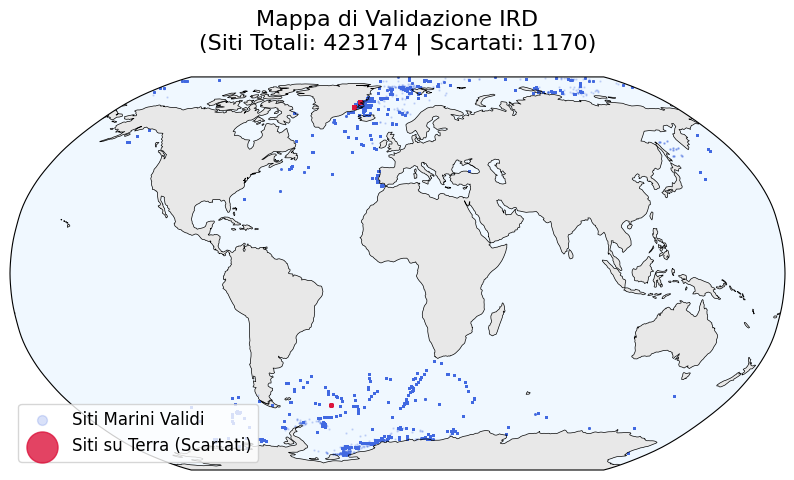

In [18]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(1, 1, 1, projection=crs.Robinson())

ax.set_global()
ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.5)
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

# Siti validi (in mare)
validi = df01_clean[df01_clean['is_on_land'] == False]
# Siti su terra (identificati come errore)
su_terra = df01_clean[df01_clean['is_on_land'] == True]

print(f"Tracciamento di {len(validi)} siti validi e {len(su_terra)} siti su terra...")

ax.scatter(validi['Longitude'], validi['Latitude'],
           transform=crs.PlateCarree(), color='royalblue', s=0.5, alpha=0.2, label='Siti Marini Validi')

ax.scatter(su_terra['Longitude'], su_terra['Latitude'],
           transform=crs.PlateCarree(), color='crimson', s=5, alpha=0.8, label='Siti su Terra (Scartati)')

plt.title(f"Mappa di Validazione IRD\n(Siti Totali: {len(df01_clean)} | Scartati: {len(su_terra)})",
          fontsize=16, pad=20)
plt.legend(markerscale=10, loc='lower left', frameon=True, fontsize=12)

plt.show()

# Controllo sui range dei dati

In [19]:
errori_trovati = 0

# Controllare di ogni colonna
for colonna in ird_columns:
    if colonna in df01_validi.columns:

        # Ci sono valori negativi?
        maschera_negativi = df01_validi[colonna] < 0
        valori_negativi_count = maschera_negativi.sum()
        if valori_negativi_count > 0:
            print(f"ATTENZIONE: Trovati {valori_negativi_count} valori NEGATIVI in '{colonna}'. Li correggo in NaN.")
            df01_validi.loc[maschera_negativi, colonna] = np.nan
            errori_trovati += 1

        # Se è la colonna delle percentuali, ci sono valori oltre il 100?
        if colonna == 'IRD [%]':
            maschera_oltre_100 = df01_validi[colonna] > 100
            valori_oltre_100_count = maschera_oltre_100.sum()
            if valori_oltre_100_count > 0:
                print(f"ATTENZIONE: Trovati {valori_oltre_100_count} valori SUPERIORI A 100 in '{colonna}'. Li correggo in NaN.")
                df01_validi.loc[maschera_oltre_100, colonna] = np.nan
                errori_trovati += 1

if errori_trovati == 0:
    print("Tutti i valori numerici dell'IRD rientravano già nei range logici.")

ATTENZIONE: Trovati 66 valori SUPERIORI A 100 in 'IRD [%]'. Li correggo in NaN.
ATTENZIONE: Trovati 9 valori NEGATIVI in 'IRD [arbitrary units]'. Li correggo in NaN.


# Divisione dati singoli dalle serie concatenate

Conta del numero di misurazioni che ci sono per ogni coppia di coordinate

In [20]:
dataset_per_analisi = df01_validi.copy()
conteggi_siti = dataset_per_analisi.groupby(['Latitude', 'Longitude']).size().reset_index(name='numero_misurazioni')
df_completo_clean = pd.merge(dataset_per_analisi, conteggi_siti, on=['Latitude', 'Longitude'])

In [21]:
df_singoli = df_completo_clean[df_completo_clean['numero_misurazioni'] == 1].copy()
df_serie = df_completo_clean[df_completo_clean['numero_misurazioni'] > 1].copy()

In [22]:
print(f"Misurazioni totali perfettamente pulite: {len(dataset_per_analisi)}")
print(f"Siti con misurazione singola (campioni superficiali): {len(df_singoli)}")
print(f"Siti con serie storiche (carote di sedimento): {len(df_serie[['Latitude', 'Longitude']].drop_duplicates())}")

Misurazioni totali perfettamente pulite: 422004
Siti con misurazione singola (campioni superficiali): 501
Siti con serie storiche (carote di sedimento): 698


In [23]:
df_serie.head()

,Latitude,Longitude,Event Label,Date/Time,Elevation [m a.s.l.],Depth sed [m],Age [ka BP],Depth water [m],Ord No,IRD gravel [#/10 cm**3],...,Age dated [ka],File name,Comm,Origin of Values,lat_orig,lon_orig,flag_problem,fix_type,is_on_land,numero_misurazioni
1,-78.0880,-36.39200,PS1621-1,1988-02-01T06:43:00,-531.0,0.00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,https://doi.pangaea.de/10.1594/PANGAEA.54277,-78.0880,-36.39200,False,none,False,2
2,-78.0880,-36.39200,PS1621-2,1988-02-01T11:33:00,-510.0,0.00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,https://doi.pangaea.de/10.1594/PANGAEA.54277,-78.0880,-36.39200,False,none,False,2
5,-78.0325,-37.54616,PS1620-2,1988-01-31T15:40:00,-1094.0,0.01,NaN,NaN,NaN,4.0,...,NaN,NaN,NaN,https://doi.pangaea.de/10.1594/PANGAEA.53356,-78.0325,-37.54616,False,none,False,39
6,-78.0325,-37.54616,PS1620-2,1988-01-31T15:40:00,-1094.0,0.02,NaN,NaN,NaN,8.0,...,NaN,NaN,NaN,https://doi.pangaea.de/10.1594/PANGAEA.53356,-78.0325,-37.54616,False,none,False,39
7,-78.0325,-37.54616,PS1620-2,1988-01-31T15:40:00,-1094.0,0.03,NaN,NaN,NaN,8.0,...,NaN,NaN,NaN,https://doi.pangaea.de/10.1594/PANGAEA.53356,-78.0325,-37.54616,False,none,False,39


In [24]:
contenitore_siti = {}

# Raggruppiamo df_serie per coordinate
for coordinate, dati_sito in df_serie.groupby(['Latitude', 'Longitude']):
    # Ordiniamo i dati partendo dal fondale (Depth) andando in profondità
    if 'Depth sed [m]' in dati_sito.columns:
        dati_ordinati = dati_sito.sort_values(by=['Depth sed [m]', 'Event Label'])
    else:
        dati_ordinati = dati_sito.sort_values(by='Event Label')

    # Inseriamo i dati nel dizionario usando le coordinate come chiave
    contenitore_siti[coordinate] = dati_ordinati

print(f"Contenitore creato! Abbiamo {len(contenitore_siti)} punti geografici con serie storiche all'interno.")

Contenitore creato! Abbiamo 698 punti geografici con serie storiche all'interno.


# Mappe

In [25]:
def disegna_mappe_finali(df_dati, titolo_categoria):
    for colonna in ird_columns:
        if colonna not in df_dati.columns:
            continue

        # Record che hanno un valore reale
        df_plot = df_dati.dropna(subset=[colonna])
        if len(df_plot) == 0: continue

        # Calcolo della media per sito
        df_mappa = df_plot.groupby(['Latitude', 'Longitude'])[colonna].mean().reset_index()

        # Creazione della mappa
        fig = plt.figure(figsize=(12, 7))
        ax = fig.add_subplot(1, 1, 1, projection=crs.Robinson())
        ax.set_global()
        ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.7)
        ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

        # Scatter plot con colormap
        scatter = ax.scatter(df_mappa['Longitude'], df_mappa['Latitude'],
                             c=df_mappa[colonna], cmap='viridis',
                             transform=crs.PlateCarree(), s=25, alpha=0.8,
                             edgecolor='black', linewidth=0.2)

        # Aggiunta della barra dei colori
        cbar = plt.colorbar(scatter, ax=ax, shrink=0.5, pad=0.05)
        cbar.set_label(f"Valore Medio: {colonna}", fontsize=10)

        plt.title(f"Distribuzione {titolo_categoria}\nUnità: {colonna}", fontsize=14)
        plt.show()

Mappe per dati singoli:


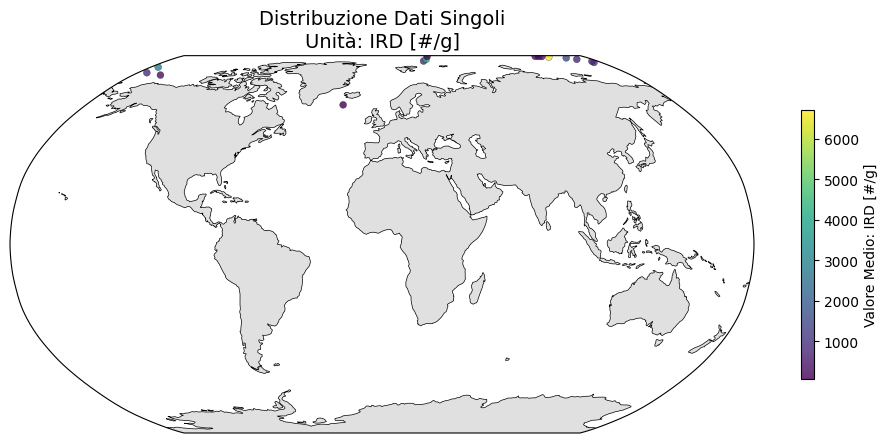

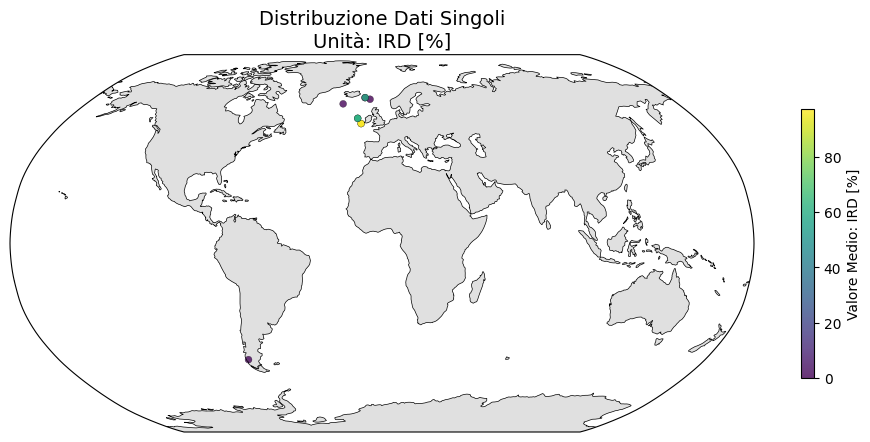

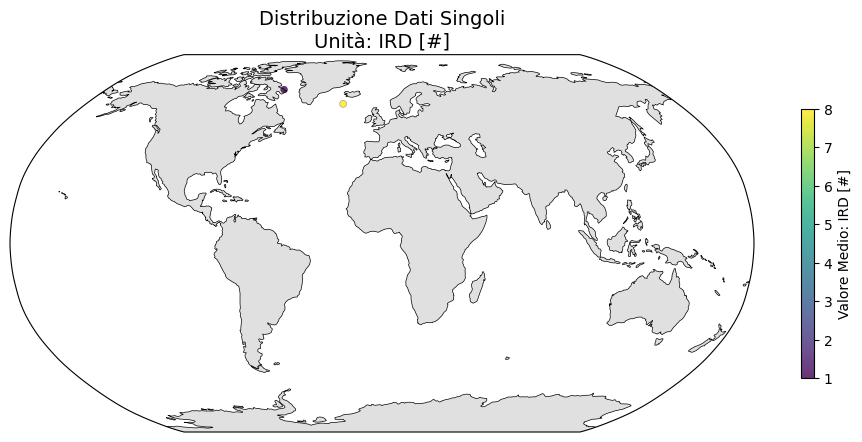

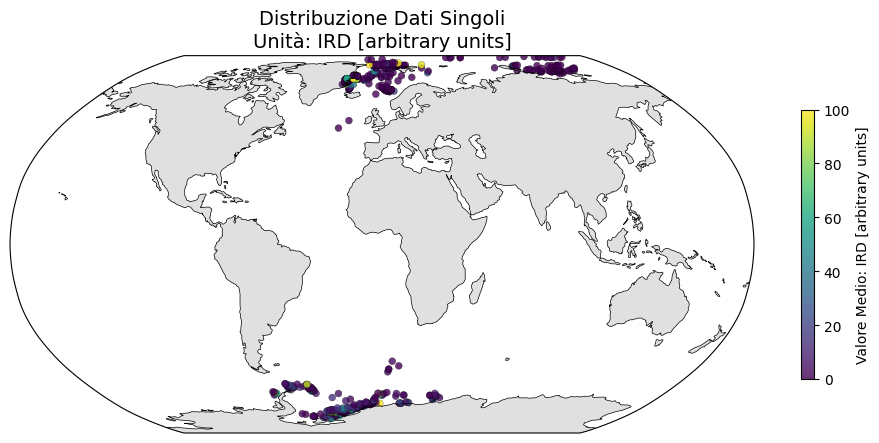

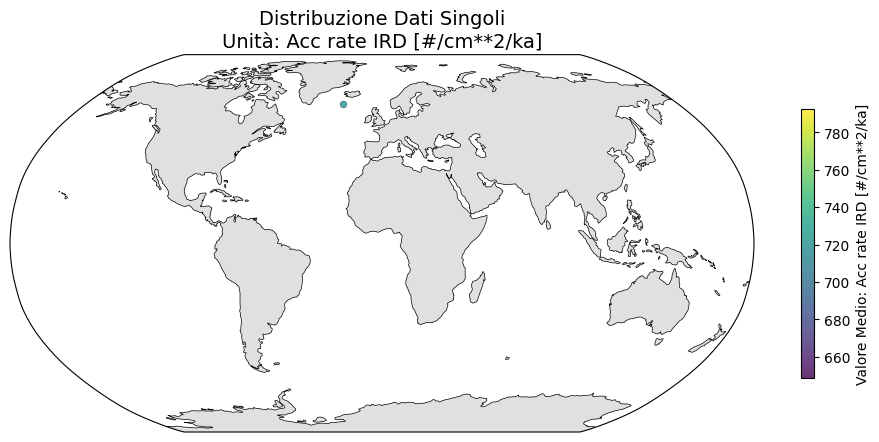

In [26]:
print("Mappe per dati singoli:")
disegna_mappe_finali(df_singoli, "Dati Singoli")

Mappe per serie storiche:


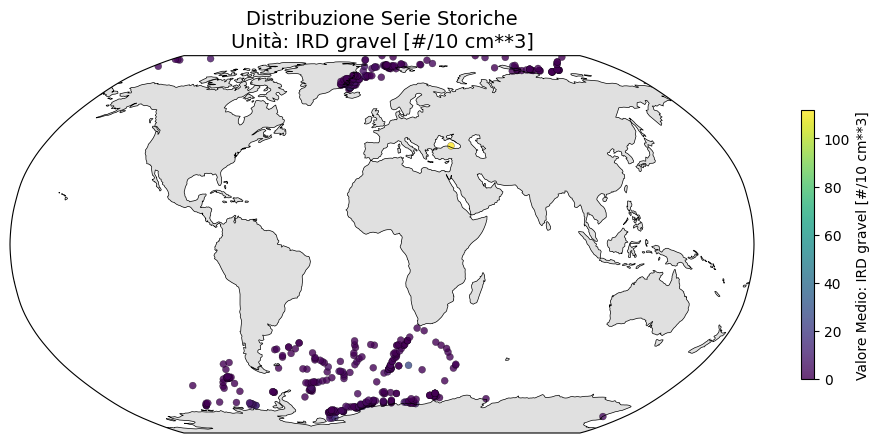

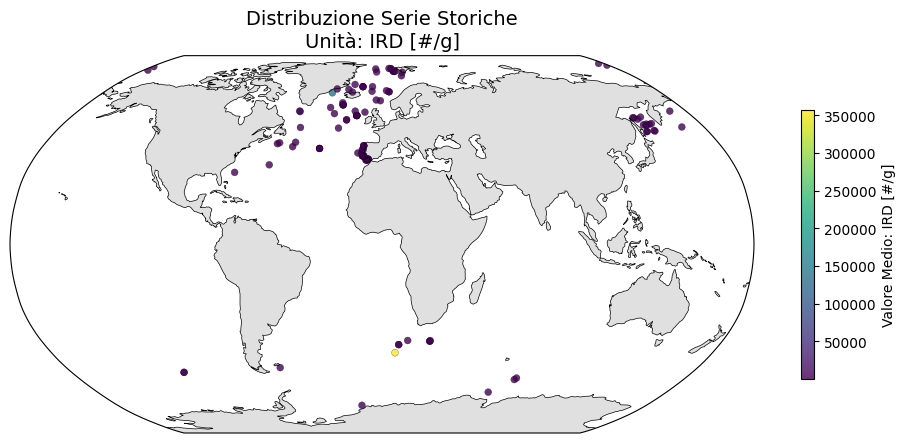

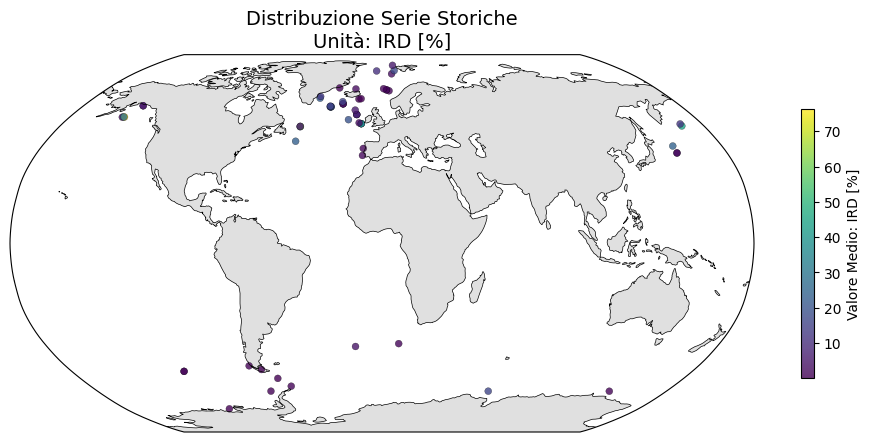

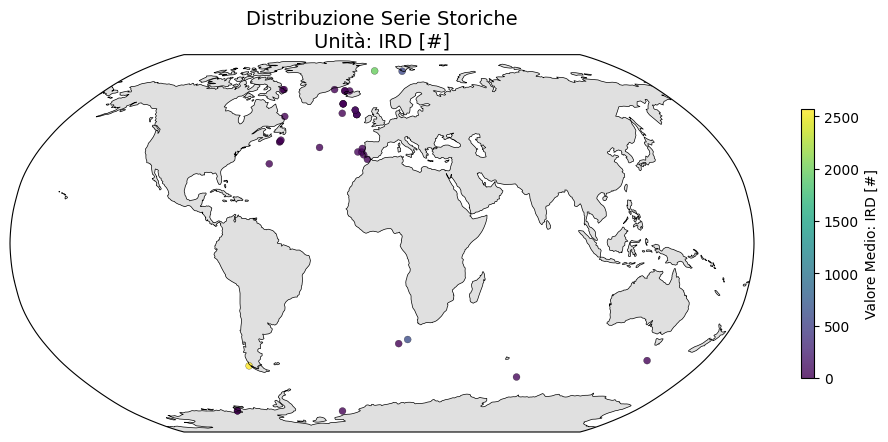

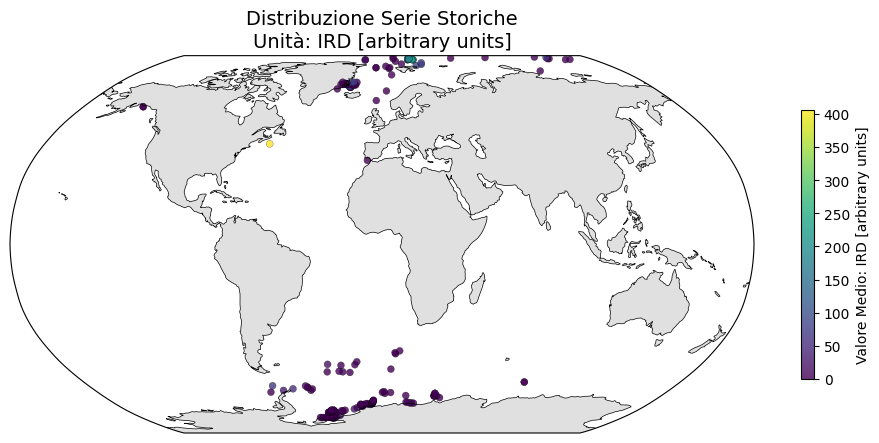

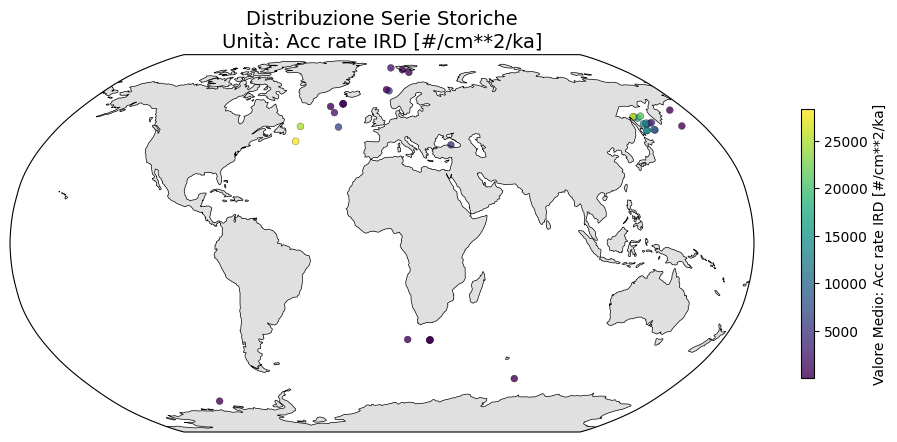

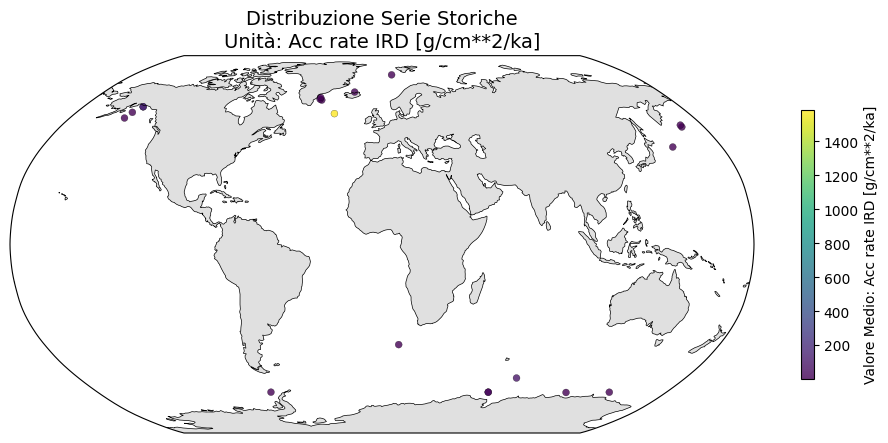

In [27]:
print("Mappe per serie storiche:")
disegna_mappe_finali(df_serie, "Serie Storiche")

# Individuazione Variabili d'interesse per ogni Sito

Lista di "metadati" da ignorare

In [28]:
colonne_da_ignorare = ['Latitude', 'Longitude', 'Event Label', 'Date/Time', 'Elevation [m a.s.l.]',
                       'Ord No', 'File name', 'Comm', 'Origin of Values',
                       'lat_orig', 'lon_orig', 'flag_problem', 'fix_type', 'is_on_land', 'numero_misurazioni']

Prendiamo i primi 5 siti dal nostro contenitore

In [29]:
siti_di_test = list(contenitore_siti.keys())

for coordinate in siti_di_test:
    dati_sito = contenitore_siti[coordinate]

    # Recupero del nome del sito
    nome_carota = dati_sito['Event Label'].dropna().unique()[0] if 'Event Label' in dati_sito.columns else "Sconosciuto"

    print(f"\nSito: {nome_carota} | Coordinate: {coordinate}")

    variabili_trovate = []

    for colonna in dati_sito.columns:
        if colonna not in colonne_da_ignorare:

            # Quanti dati validi (non NaN) ci sono in questa colonna?
            conteggio_validi = dati_sito[colonna].count()

            # Se c'è ALMENO un numero valido, allora questa variabile è "disponibile" per questo sito!
            if conteggio_validi > 0:
                variabili_trovate.append((colonna, conteggio_validi))

    if len(variabili_trovate) > 0:
        print(f"Trovate {len(variabili_trovate)} variabili/misurazioni:")
        for nome_var, conteggio in variabili_trovate:
            print(f"  - {nome_var} ({conteggio} dati)")
    else:
        print("Nessuna variabile scientifica utile trovata in questa carota.")


Sito: PS1621-1 | Coordinate: (np.float64(-78.088), np.float64(-36.392))
Trovate 2 variabili/misurazioni:
  - Depth sed [m] (2 dati)
  - IRD [arbitrary units] (2 dati)

Sito: PS1620-2 | Coordinate: (np.float64(-78.0325), np.float64(-37.54616))
Trovate 2 variabili/misurazioni:
  - Depth sed [m] (39 dati)
  - IRD gravel [#/10 cm**3] (39 dati)

Sito: PS1619-1 | Coordinate: (np.float64(-78.03133), np.float64(-39.34233))
Trovate 2 variabili/misurazioni:
  - Depth sed [m] (44 dati)
  - IRD gravel [#/10 cm**3] (44 dati)

Sito: PS1217-1 | Coordinate: (np.float64(-77.73729), np.float64(-36.42969))
Trovate 2 variabili/misurazioni:
  - Depth sed [m] (3 dati)
  - IRD [arbitrary units] (3 dati)

Sito: PS1216-1 | Coordinate: (np.float64(-77.69), np.float64(-37.065))
Trovate 2 variabili/misurazioni:
  - Depth sed [m] (6 dati)
  - IRD [arbitrary units] (6 dati)

Sito: PS1276-1 | Coordinate: (np.float64(-77.6532), np.float64(-44.8867))
Trovate 2 variabili/misurazioni:
  - Depth sed [m] (5 dati)
  - IRD

# Armonizzazione delle Unità di Misura

In [30]:
colonne_ird_possibili = [
    'IRD gravel [#/10 cm**3]', 'IRD [#/g]', 'IRD [%]', 'IRD [#]',
    'Acc rate IRD [#/cm**2/ka]', 'Acc rate IRD [g/cm**2/ka]', 'IRD [arbitrary units]'
]

Raccolta dei dati divisi per unità di misura

In [31]:
# Raccogliamo i valori per unità da ENTRAMBE le sorgenti:
# - contenitore_siti (perforazioni, n>1 misura per coordinate)
# - df_singoli (campioni superficiali, 1 sola misura per coordinate)
# Includere df_singoli è necessario per ottenere una std globale corretta.
dati_globali_per_unita = {col: [] for col in colonne_ird_possibili}

for df in contenitore_siti.values():
    for col in colonne_ird_possibili:
        if col in df.columns:
            valori_validi = df[col].dropna().values
            dati_globali_per_unita[col].extend(valori_validi)

# Aggiungiamo anche i singoli campioni superficiali
for col in colonne_ird_possibili:
    if col in df_singoli.columns:
        valori_validi = df_singoli[col].dropna().values
        dati_globali_per_unita[col].extend(valori_validi)


Calcolo della deviazione standard globale (solo su valori positivi)

In [32]:
std_positivi_globale = {}

for col, valori in dati_globali_per_unita.items():
    valori_arr = np.array(valori)
    # Filtro per i valori strettamente maggiori di zero
    valori_positivi = valori_arr[valori_arr > 0]

    if len(valori_positivi) > 0:
        #std_positivi_globale[col] = valori_positivi.std()
        std_positivi_globale[col] = valori_positivi.std(ddof=1)
        print(f"Unità '{col}': trovati {len(valori_positivi)} valori positivi. Std calcolata: {std_positivi_globale[col]:.4f}")
    else:
        std_positivi_globale[col] = 1.0 # Sicurezza per evitare divisioni per zero

Unità 'IRD gravel [#/10 cm**3]': trovati 98040 valori positivi. Std calcolata: 11.0638
Unità 'IRD [#/g]': trovati 27406 valori positivi. Std calcolata: 303671.0877
Unità 'IRD [%]': trovati 27426 valori positivi. Std calcolata: 15.6200
Unità 'IRD [#]': trovati 12801 valori positivi. Std calcolata: 986.5153
Unità 'Acc rate IRD [#/cm**2/ka]': trovati 13042 valori positivi. Std calcolata: 10718.4126
Unità 'Acc rate IRD [g/cm**2/ka]': trovati 2982 valori positivi. Std calcolata: 1001.0018
Unità 'IRD [arbitrary units]': trovati 7353 valori positivi. Std calcolata: 72.4399


Calcolo per ogni singolo sito

In [33]:
# Normalizziamo IRD_Index per i siti con serie storiche (contenitore_siti)
siti_armonizzati = 0
for df in contenitore_siti.values():
    colonna_target = None
    for col in colonne_ird_possibili:
        if col in df.columns and df[col].count() > 0:
            colonna_target = col
            break

    if colonna_target:
        std_globale = std_positivi_globale[colonna_target]
        df['IRD_Index'] = df[colonna_target].apply(lambda x: x / std_globale if x > 0 else x)
        df['Unita_Originale_IRD'] = colonna_target
        siti_armonizzati += 1
    else:
        df['IRD_Index'] = np.nan

# Normalizziamo IRD_Index anche per i campioni superficiali (df_singoli)
df_singoli['IRD_Index'] = np.nan
df_singoli['Unita_Originale_IRD'] = None
for col in colonne_ird_possibili:
    if col in df_singoli.columns:
        std_globale = std_positivi_globale.get(col, 1.0)
        mask = df_singoli[col].notna() & df_singoli['IRD_Index'].isna()
        df_singoli.loc[mask, 'IRD_Index'] = df_singoli.loc[mask, col].apply(
            lambda x: x / std_globale if x > 0 else x
        )
        df_singoli.loc[mask, 'Unita_Originale_IRD'] = col

n_singoli_arm = df_singoli['IRD_Index'].notna().sum()
print(f"{siti_armonizzati} siti da contenitore_siti armonizzati")
print(f"{n_singoli_arm} campioni superficiali (df_singoli) armonizzati")


698 siti da contenitore_siti armonizzati
492 campioni superficiali (df_singoli) armonizzati


## Mappa

Estrazione valori superficiali

In [34]:
dati_mappa_superficie = []

for coordinate, df in contenitore_siti.items():
    if 'IRD_Index' in df.columns and df['IRD_Index'].count() > 0:
        df_valido = df.dropna(subset=['IRD_Index'])

        if not df_valido.empty:
            if 'Depth sed [m]' in df_valido.columns and df_valido['Depth sed [m]'].count() > 0:
                df_valido = df_valido.sort_values(by='Depth sed [m]', ascending=True)
            elif 'Age [ka BP]' in df_valido.columns and df_valido['Age [ka BP]'].count() > 0:
                df_valido = df_valido.sort_values(by='Age [ka BP]', ascending=True)

            ird_superficie = df_valido['IRD_Index'].iloc[0]
            lat, lon = coordinate
            dati_mappa_superficie.append({'Lat': lat, 'Lon': lon, 'IRD_Superficie': ird_superficie})

In [35]:
df_mappa2 = pd.DataFrame(dati_mappa_superficie)
print(f"Estratti {len(df_mappa2)} valori superficiali")

Estratti 698 valori superficiali


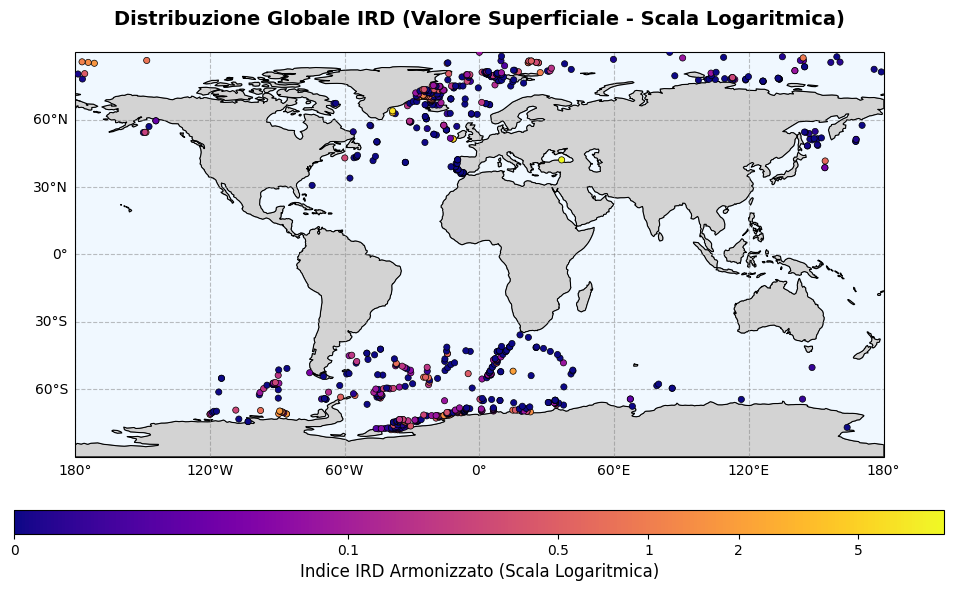

In [36]:
fig = plt.figure(figsize=(12, 7))
ax = plt.axes(projection=crs.PlateCarree())
ax.set_global()

ax.add_feature(cfeature.LAND, facecolor='lightgray', edgecolor='black', linewidth=0.5)
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)

gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5, color='gray')
gl.top_labels = False
gl.right_labels = False

ax.set_title("Distribuzione Globale IRD (Valore Superficiale - Scala Logaritmica)", fontsize=14, fontweight='bold', pad=20)

valore_massimo = df_mappa2['IRD_Superficie'].max()

scatter = ax.scatter(df_mappa2['Lon'], df_mappa2['Lat'],
                     transform=crs.PlateCarree(),
                     c=df_mappa2['IRD_Superficie'], cmap='plasma',
                     norm=mcolors.SymLogNorm(linthresh=0.1, vmin=0, vmax=valore_massimo),
                     s=20, edgecolors='black', linewidths=0.5, zorder=5)

# Barra dei colori
tck = [0, 0.1, 0.5, 1, 2, 5, 10]
cbar = plt.colorbar(scatter, orientation='horizontal', pad=0.1, aspect=40, ax=ax, ticks=tck)

cbar.ax.set_xticklabels([str(t) for t in tck])

cbar.set_label('Indice IRD Armonizzato (Scala Logaritmica)', fontsize=12)

plt.show()
plt.show()

# Ricerca Variabili Accessorie

In [37]:
carote = ["PS97/085-3", "162-983C", "306-U1314"]

Parole chiave

In [38]:
keywords_ausiliarie = ["age", "grain size", "isotope", "temperature"]

In [39]:
max_risulati_per_kw = 10
pausa = 0.4

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
                  "AppleWebKit/537.36 (KHTML, like Gecko) "
                  "Chrome/120.0.0.0 Safari/537.36",
}

Ricerca su Datacite

In [40]:
def cerca_datacite(carota: str, keyword: str, max_n: int = 10) -> list[dict]:
    params = {
        "query":      f'publisher:PANGAEA AND "{carota}" AND ({keyword})',
        "page[size]": max_n,
    }
    try:
        r = requests.get("https://api.datacite.org/dois",
                         params=params, headers=headers, timeout=15)
        if r.status_code != 200:
            print(f"    [DataCite] HTTP {r.status_code} — carota='{carota}', kw='{keyword}'")
            return []

        risultati = []
        for item in r.json().get("data", []):
            attrs = item["attributes"]
            doi   = attrs.get("doi", "")
            if not doi:
                continue
            titolo = next(
                (t.get("title", "") for t in attrs.get("titles", [])), "N/A"
            )
            creators = attrs.get("creators", [])
            if creators:
                c0    = creators[0]
                primo = c0.get("familyName") or c0.get("name", "")
                autori = primo + (" et al." if len(creators) > 1 else "")
            else:
                autori = ""
            anno = str(attrs.get("publicationYear") or "")
            risultati.append({
                "doi":             doi,
                "citation_label":  f"{autori} ({anno}): {titolo}",
                "keyword_trovata": keyword,
            })
        return risultati

    except Exception as e:
        print(f"    [DataCite] Errore: {e}")
        return []

Estrazione metadati e colonne dal file testuale PANGAEA

In [41]:
def estrai_info_pangaea(doi: str) -> dict:
    info = {
        "citation": "",
        "abstract": "",
        "size":     "",
        "colonne":  [],
        "errore":   None,
    }

    doi_path = doi
    for prefix in ("https://doi.org/", "http://doi.org/", "https://doi.pangaea.de/"):
        if doi.lower().startswith(prefix):
            doi_path = doi[len(prefix):]
            break

    url = f"https://doi.pangaea.de/{doi_path}?format=textfile"

    try:
        r = requests.get(url, headers=headers, timeout=25, allow_redirects=True)

        if r.status_code != 200:
            if r.status_code == 400:
                info["errore"] = "Collezione/dataset padre (nessun file TSV diretto)"
            else:
                info["errore"] = f"HTTP {r.status_code}"
            return info

        if "html" in r.headers.get("Content-Type", "").lower():
            info["errore"] = "Collezione/dataset padre (nessun file TSV diretto)"
            return info

        righe = r.text.splitlines()
        campo_attivo = None

        for idx, riga in enumerate(righe):

            # Fine blocco metadati
            if riga.strip() == "*/":
                if idx + 1 < len(righe):
                    riga_col = righe[idx + 1]
                    if riga_col and not riga_col.startswith("/*"):
                        info["colonne"] = [
                            c.strip() for c in riga_col.split("\t") if c.strip()
                        ]
                break

            # Inizia con tab
            if riga.startswith("\t") and campo_attivo:
                testo = riga.strip()
                if testo:
                    info[campo_attivo] += " " + testo
                continue

            # Riga campo
            if "\t" in riga:
                chiave, _, valore = riga.partition("\t")
                chiave = chiave.strip().rstrip(":")

                if chiave == "Citation":
                    info["citation"] = valore.strip()
                    campo_attivo = "citation"
                elif chiave == "Abstract":
                    info["abstract"] = valore.strip()
                    campo_attivo = "abstract"
                elif chiave == "Size":
                    info["size"] = valore.strip()
                    campo_attivo = "size"
                else:
                    campo_attivo = None

        # Troncamento abstract per leggibilità
        if len(info["abstract"]) > 300:
            info["abstract"] = info["abstract"][:300] + "..."

        # Pulizia citation: tenuta solo la parte prima del link DOI
        if info["citation"] and ", https://" in info["citation"]:
            info["citation"] = info["citation"].split(", https://")[0].strip()

    except Exception as e:
        info["errore"] = str(e)

    return info

Main

In [42]:
def main(carote_list, keywords_aux):

    for carota in carote:
        print(f"\n{'━' * 80}")
        print(f"  CAROTA: {carota}")
        print(f"{'━' * 80}")

        tutti: dict[str, dict] = {}

        for kw in keywords_aux:
            time.sleep(pausa)
            for ds in cerca_datacite(carota, kw, max_risulati_per_kw):
                doi = ds["doi"]
                if doi and doi not in tutti:
                    tutti[doi] = ds

        if not tutti:
            print("    Nessun dataset trovato per questa carota.")
            continue

        print(f"    {len(tutti)} dataset unici trovati.\n")

        for i, (doi, ds) in enumerate(tutti.items(), start=1):
            doi_url = f"https://doi.org/{doi}" if not doi.startswith("http") else doi

            time.sleep(pausa)
            info = estrai_info_pangaea(doi)

            citation = info["citation"] or ds["citation_label"]
            print(f"  {i:>2}. {citation}")

            if info["abstract"]:
                print(f"       Abstract: {info['abstract']}")

            if info["errore"]:
                # Collezioni: segnaliamo senza mostrare come errore tecnico
                if "Collezione" in info["errore"]:
                    print(f"       Contiene sotto-dataset, nessuna colonna diretta")
                else:
                    print(f"       {info['errore']}")
            else:
                size_str = info["size"] or "N/A"
                print(f"       Size: {size_str}  |  Keyword: [{ds['keyword_trovata']}]")

                if info["colonne"]:
                    N       = 10
                    col_str = "  |  ".join(info["colonne"][:N])
                    extra   = (f"  (+{len(info['colonne']) - N} altre)"
                               if len(info["colonne"]) > N else "")
                    print(f"       COLONNE: {col_str}{extra}")
                else:
                    print(f"       Nessuna colonna estratta.")

            print(f"        {doi_url}")
            print()

if __name__ == "__main__":
    main(carote, keywords_ausiliarie)


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  CAROTA: PS97/085-3
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    18 dataset unici trovati.

   1. Loftfield, Julia; Nowaczyk, Norbert R; Lembke-Jene, Lester; Frederichs, Thomas; Lachner, Johannes; Lamy, Frank; Rugel, Georg; Stübner, Konstanze; Adolphi, Florian (2026): Age model of sediment core PS97/085-3 [dataset]. PANGAEA
       Abstract: Age model of PS97/085-3 28 – 58 ka BP. Model is based on correlating relative paleointensities and magnetic inclination with the Black Sea core stack of Wu et al. (2021), on the correlation of XRF scan derived ln(Ca/Ti) to EDC temperature anomalies (AICC2023), and on the correlation of ln(Ca/Ti) and...
       Size: 15 data points  |  Keyword: [age]
       COLONNE: Depth sed [m]  |  Age [ka BP]  |  Comm
        https://doi.org/10.1594/pangaea.980572

   2. Loftfield, Julia; Nowaczyk, Norbert R; Lembke-Jene, Lester; Frederichs, Th

# Analisi Serie Temporali

## Ricerca Siti per Analisi Serie Temporali

In [43]:
colonne_eta_possibili = ['Age [ka BP]', 'Age dated [ka]', 'Age model [ka]']

In [44]:
carote_d_oro = []

for coordinate, df in contenitore_siti.items():
  if 'IRD_Index' in df.columns and df['IRD_Index'].count() > 5:
        colonna_eta_valida = None
        conteggio_eta = 0

        for col_eta in colonne_eta_possibili:
            if col_eta in df.columns:
                validi = df[col_eta].count()
                if validi > 5:
                    colonna_eta_valida = col_eta
                    conteggio_eta = validi
                    break

        if colonna_eta_valida:
            nome_carota = df['Event Label'].iloc[0] if 'Event Label' in df.columns else "Sconosciuto"
            carote_d_oro.append({
                'Nome': nome_carota,
                'Coordinate': coordinate,
                'Colonna_Eta': colonna_eta_valida,
                'Punti_Dato': conteggio_eta
            })

In [45]:
carote_d_oro_ordinate = sorted(carote_d_oro, key=lambda x: x['Punti_Dato'], reverse=True)

In [46]:
print(f"{len(carote_d_oro_ordinate)} siti completi (con Età e Indice IRD).")

if len(carote_d_oro_ordinate) > 0:
    print("\nLe 5 carote migliori per il grafico temporale:")
    for carota in carote_d_oro_ordinate[:5]:
        print(f"  - {carota['Nome']} | {carota['Punti_Dato']} misurazioni valide in {carota['Colonna_Eta']}")

130 siti completi (con Età e Indice IRD).

Le 5 carote migliori per il grafico temporale:
  - PS97/085-3 | 49700 misurazioni valide in Age [ka BP]
  - 162-983C | 7059 misurazioni valide in Age [ka BP]
  - 306-U1314 | 3019 misurazioni valide in Age [ka BP]
  - 162-983B | 2757 misurazioni valide in Age [ka BP]
  - 162-983A | 2445 misurazioni valide in Age [ka BP]


## Analisi Serie Temporali (Età Vs IRD)

Esempio per la carota 162-983C

In [47]:
nome_carota_scelta = "162-983C"
coordinate_scelte = (60.4036, -23.6408)

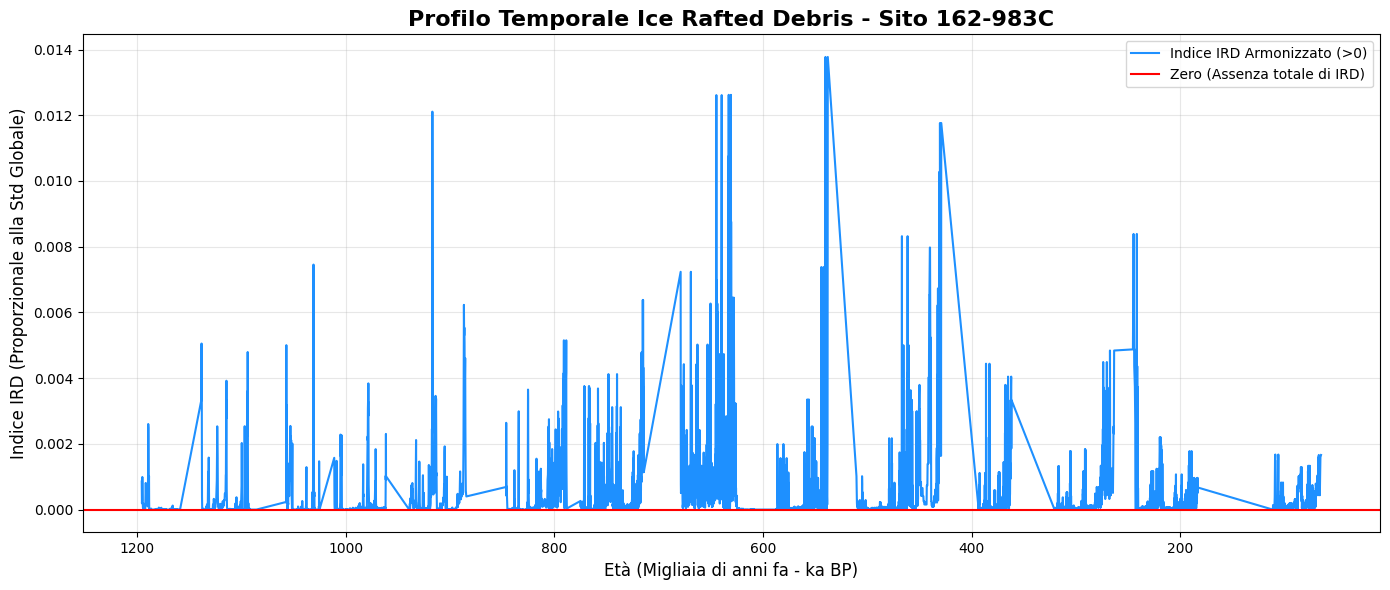

7059 misurazioni!


In [48]:
if coordinate_scelte in contenitore_siti:
    df_plot = contenitore_siti[coordinate_scelte].copy()

    # Filtro usando la nuova colonna IRD_Index
    df_plot = df_plot.dropna(subset=['Age [ka BP]', 'IRD_Index'])
    df_plot = df_plot.sort_values(by='Age [ka BP]')

    if len(df_plot) > 0:
        plt.figure(figsize=(14, 6))

        # Disegno della linea
        plt.plot(df_plot['Age [ka BP]'], df_plot['IRD_Index'],
                 color='dodgerblue', linewidth=1.5, label='Indice IRD Armonizzato (>0)')

        # La linea rossa sullo zero
        plt.axhline(0, color='red', linestyle='-', linewidth=1.5, label='Zero (Assenza totale di IRD)')

        plt.title(f"Profilo Temporale Ice Rafted Debris - Sito {nome_carota_scelta}", fontsize=16, fontweight='bold')
        plt.xlabel("Età (Migliaia di anni fa - ka BP)", fontsize=12)
        plt.ylabel("Indice IRD (Proporzionale alla Std Globale)", fontsize=12)

        plt.gca().invert_xaxis()
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

        print(f"{len(df_plot)} misurazioni!")
    else:
        print("Impossibile generare il grafico: dati insufficienti dopo la pulizia.")
else:
    print("Coordinate non trovate nel contenitore siti.")

# Mappa Riassuntiva Carote (Age, Depth)

Estrazione dati

In [49]:
dati_mappa_disp = []

for coordinate, df in contenitore_siti.items():
    lat, lon = coordinate
    ha_eta = 'Age [ka BP]' in df.columns and df['Age [ka BP]'].count() > 0
    ha_prof = 'Depth sed [m]' in df.columns and df['Depth sed [m]'].count() > 0

    if ha_eta and ha_prof: stato = 'Entrambe (Età e Profondità)'
    elif ha_eta: stato = 'Solo Età'
    elif ha_prof: stato = 'Solo Profondità'
    else: stato = 'Nessuna'

    dati_mappa_disp.append({'Lat': lat, 'Lon': lon, 'Stato': stato})

In [50]:
df_mappa3 = pd.DataFrame(dati_mappa_disp)
print(f"Classificati {len(df_mappa3)} siti.")

Classificati 698 siti.


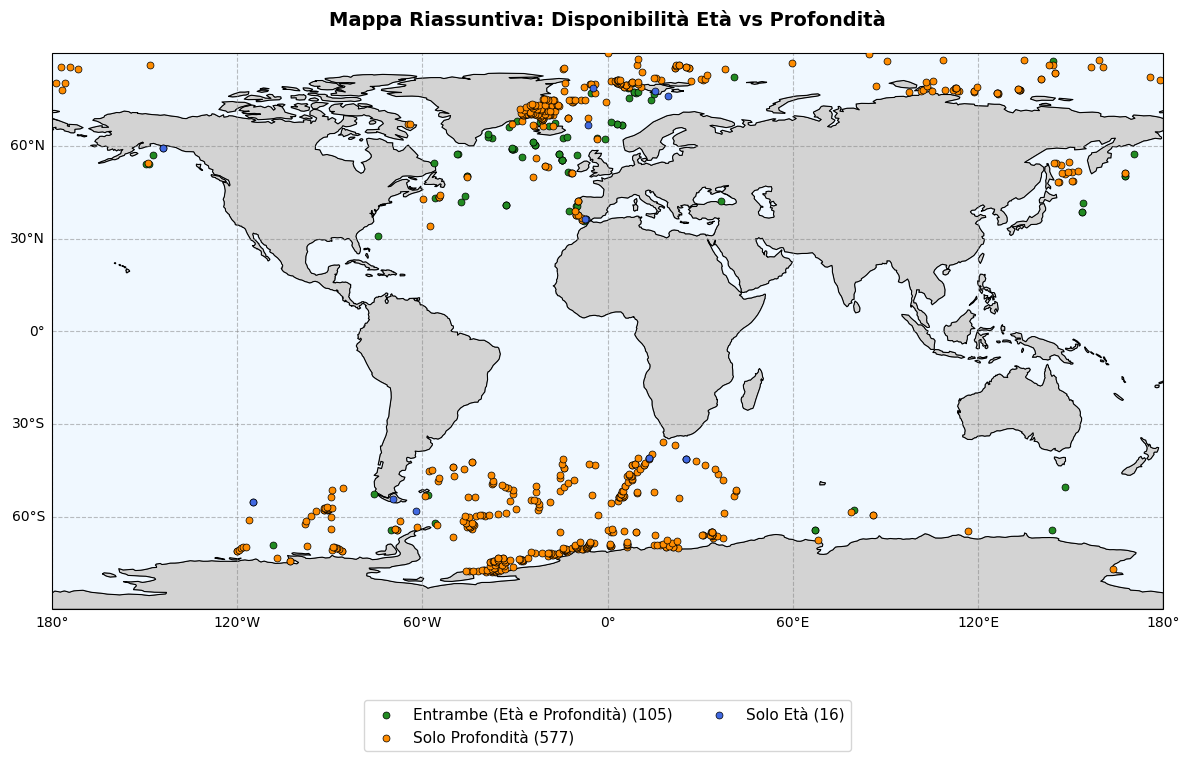

In [51]:
fig = plt.figure(figsize=(12, 7))

ax = plt.axes(projection=crs.PlateCarree())
ax.set_global()

ax.add_feature(cfeature.LAND, facecolor='lightgray', edgecolor='black', linewidth=0.5)
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)

gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5, color='gray')
gl.top_labels = False
gl.right_labels = False

ax.set_title("Mappa Riassuntiva: Disponibilità Età vs Profondità", fontsize=14, fontweight='bold', pad=20)

colori = {
    'Entrambe (Età e Profondità)': 'forestgreen',
    'Solo Profondità': 'darkorange',
    'Solo Età': 'royalblue',
    'Nessuna': 'crimson'
}

for stato, colore in colori.items():
    subset = df_mappa3[df_mappa3['Stato'] == stato]
    if not subset.empty:
        ax.scatter(subset['Lon'], subset['Lat'], transform=crs.PlateCarree(),
                   color=colore, label=f"{stato} ({len(subset)})",
                   edgecolors='black', s=25, linewidths=0.5, zorder=5)

# Legenda
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=11, frameon=True)

plt.tight_layout()
plt.show()

# Mappe Temporali Carote con Age

In [52]:
intervalli = [(24, 21), (21, 18), (18, 15), (15, 12), (12, 9), (9, 6), (6, 3), (3, 0)]

Funzione per disegnare lo sfondo per ogni sottomappa

In [53]:
def setup_mappa(ax, titolo):
    ax.set_global()
    ax.add_feature(cfeature.LAND, facecolor='lightgray', edgecolor='black', linewidth=0.5)
    ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.3, color='gray')
    gl.top_labels = False
    gl.right_labels = False
    ax.set_title(titolo, fontsize=14, fontweight='bold', pad=10)

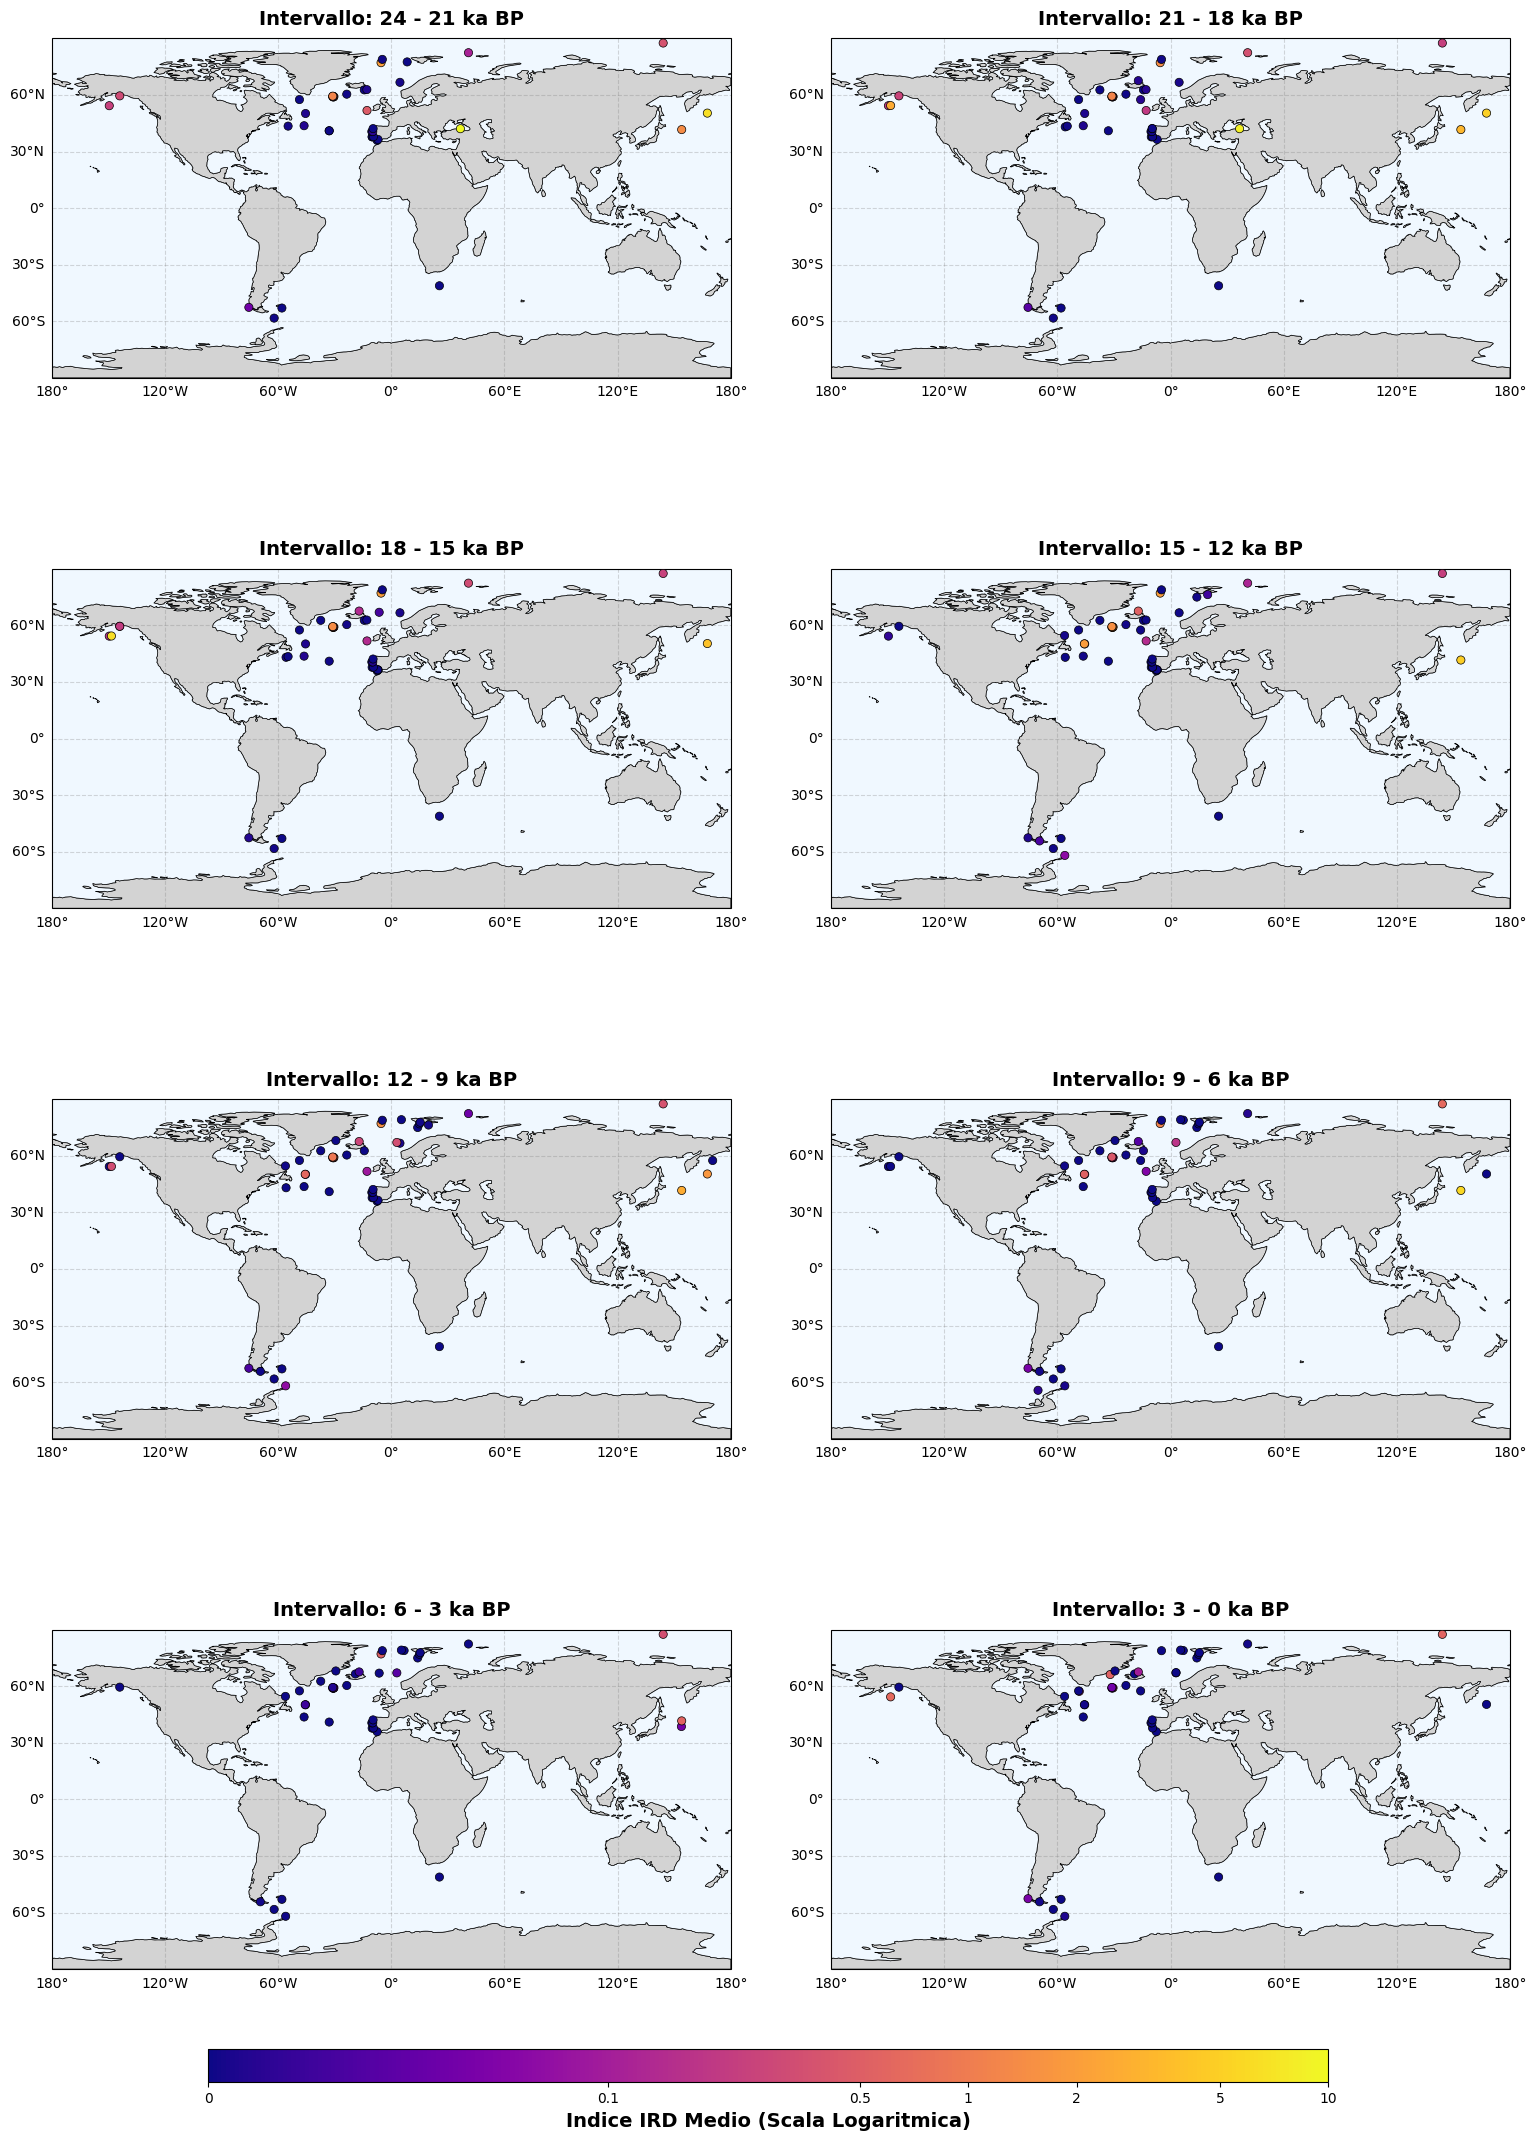

In [54]:
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(16, 22), subplot_kw={'projection': crs.PlateCarree()})
axes = axes.flatten()

scatter_plot_ref = None

# Limite massimo della barra dei colori a 10 per coprire eventuali outlier senza schiacciare
limite_massimo = 10.0

for i, (start, end) in enumerate(intervalli):
    ax = axes[i]
    setup_mappa(ax, f"Intervallo: {start} - {end} ka BP")

    dati_plot_lon = []
    dati_plot_lat = []
    dati_plot_val = []

    for coordinate, df in contenitore_siti.items():
        if 'Age [ka BP]' in df.columns and 'IRD_Index' in df.columns:
            df_val = df.dropna(subset=['Age [ka BP]', 'IRD_Index'])

            if end == 0:
                mask = (df_val['Age [ka BP]'] <= start) & (df_val['Age [ka BP]'] >= end)
            else:
                mask = (df_val['Age [ka BP]'] <= start) & (df_val['Age [ka BP]'] > end)

            dati_intervallo = df_val[mask]

            if not dati_intervallo.empty:
                dati_plot_lon.append(coordinate[1])
                dati_plot_lat.append(coordinate[0])
                dati_plot_val.append(dati_intervallo['IRD_Index'].mean())

    if dati_plot_lon:
        sc = ax.scatter(dati_plot_lon, dati_plot_lat, transform=crs.PlateCarree(),
                        c=dati_plot_val, cmap='plasma',
                        norm=mcolors.SymLogNorm(linthresh=0.1, vmin=0, vmax=limite_massimo),
                        edgecolors='black', linewidths=0.5, s=35, zorder=5)
        scatter_plot_ref = sc

plt.tight_layout(pad=3.0)

# Barra dei colori
if scatter_plot_ref:
    cbar_ax = fig.add_axes([0.15, 0.01, 0.7, 0.015])

    tck = [0, 0.1, 0.5, 1, 2, 5, 10]
    cbar = fig.colorbar(scatter_plot_ref, cax=cbar_ax, orientation='horizontal', ticks=tck)
    cbar.ax.set_xticklabels([str(t) for t in tck])

    cbar.set_label('Indice IRD Medio (Scala Logaritmica)', fontsize=14, fontweight='bold')

# Esportazione Dati

# Script di Verifica

In [55]:
cartella_output = '/content/drive/MyDrive/Further Activities/Esportazione_Dati_IRD'
cartella_carote = os.path.join(cartella_output, 'perforazioni_csv')

In [56]:
if os.path.exists(cartella_carote):
    shutil.rmtree(cartella_carote)
os.makedirs(cartella_carote, exist_ok=True)

Funzioni per il recupero dei metadati

In [57]:
# Estrazione del DOI puro della stringa raw
def _estrai_doi_numerico(doi_raw: str) -> str | None:
    first = doi_raw.split(';')[0].strip()
    m = re.search(r'(10\.\d{4,}/PANGAEA\.\d+)', first)
    return m.group(1) if m else None

In [58]:
#Chiamta al DataCite REST API e ritorno al blocco "attributes", o None se fallisce
def _get_datacite_attrs(doi_id: str) -> dict | None:
    url = f"https://api.datacite.org/dois/{doi_id}"
    try:
        r = requests.get(url, timeout=15, headers={'Accept': 'application/vnd.api+json'})
        if r.status_code == 200:
            return r.json().get('data', {}).get('attributes', {})
    except Exception:
        pass
    return None

In [59]:
# Ricerca del DOI di pubblicazione (non-PANGAEA) nella lista relatedIdentifiers
def _pub_doi_da_related(related_identifiers: list) -> str | None:
    ESCLUDI_RELAZIONI = {'IsPartOf', 'HasPart', 'IsIdenticalTo'}
    for rel in related_identifiers:
        if rel.get('relatedIdentifierType') != 'DOI':
            continue
        if rel.get('relationType') in ESCLUDI_RELAZIONI:
            continue
        doi_val = rel.get('relatedIdentifier', '')
        if 'PANGAEA' in doi_val.upper():
            continue
        return doi_val  # primo DOI di pubblicazione trovato
    return None

In [60]:
#Ricerca del DOI del dataset genitore
def _parent_doi_da_related(related_identifiers: list) -> str | None:
    for rel in related_identifiers:
        if rel.get('relationType') == 'IsPartOf' \
           and rel.get('relatedIdentifierType') == 'DOI' \
           and 'PANGAEA' in rel.get('relatedIdentifier', '').upper():
            return rel['relatedIdentifier']
    return None

In [61]:
# Recupero del titolo di una pubblicazione
def _titolo_da_datacite(doi_pub_id: str) -> str:
    attrs = _get_datacite_attrs(doi_pub_id)
    if attrs:
        titoli = attrs.get('titles', [])
        if titoli:
            return titoli[0].get('title', 'Non disponibile')
    return 'Non disponibile'

In [62]:
# Recupero autori, DOI e titolo della pubblicazione associata a un dataset PANGAEA
def get_pangaea_metadata(doi_raw: str) -> dict:
    risultato_vuoto = {
        'autori': 'Non disponibile',
        'doi_pubblicazione': 'Non disponibile',
        'titolo_pubblicazione': 'Non disponibile'
    }

    doi_id = _estrai_doi_numerico(doi_raw)
    if not doi_id:
        return risultato_vuoto

In [63]:
# Recupero autori, DOI e titolo della pubblicazione associata a un dataset PANGAEA
def get_pangaea_metadata(doi_raw: str) -> dict:
    risultato_vuoto = {
        'autori': 'Non disponibile',
        'doi_pubblicazione': 'Non disponibile',
        'titolo_pubblicazione': 'Non disponibile'
    }

    doi_id = _estrai_doi_numerico(doi_raw)
    if not doi_id:
        return risultato_vuoto

    id_numerico = doi_id.split('.')[-1]  # es. "54277"
    try:
        r = requests.get(
            f"https://elabs.pangaea.de/search",
            params={'q': f'PANGAEA.{id_numerico}', 'count': 1, 'format': 'json'},
            timeout=15
        )
        if r.status_code == 200:
            hits = r.json().get('results', [])
            if hits:
                hit = hits[0]
                # Autori dal campo 'citation' del dataset
                citation = hit.get('citation', '')
                m = re.match(r'^(.+?)\s*\(\d{4}\)', citation)
                autori = m.group(1).strip() if m else 'Non disponibile'

                # Pubblicazione dal campo 'supplementTo'
                supp = hit.get('supplementTo', {})
                doi_pub = supp.get('DOI', '')
                cit_pub = supp.get('citation', '')
                if doi_pub:
                    if not doi_pub.startswith('http'):
                        doi_pub = f"https://doi.org/{doi_pub}"
                    # Titolo dalla citazione della pubblicazione
                    m2 = re.search(r'\(\d{4}\):\s*(.+)', cit_pub)
                    titolo_pub = m2.group(1).strip() if m2 else cit_pub
                    return {
                        'autori': autori,
                        'doi_pubblicazione': doi_pub,
                        'titolo_pubblicazione': titolo_pub
                    }
                # salviamo gli autori e proviamo i livelli successivi per la pubblicazione
                autori_da_elabs = autori
            else:
                autori_da_elabs = 'Non disponibile'
        else:
            autori_da_elabs = 'Non disponibile'
    except Exception:
        autori_da_elabs = 'Non disponibile'

    attrs = _get_datacite_attrs(doi_id)
    if attrs is None:
        return {**risultato_vuoto, 'autori': autori_da_elabs}

    # Autori da DataCite
    if autori_da_elabs == 'Non disponibile':
        creators = attrs.get('creators', [])
        autori_da_elabs = '; '.join(
            c.get('name', '') for c in creators if c.get('name')
        ) or 'Non disponibile'

    related = attrs.get('relatedIdentifiers', [])

    # Tentativo diretto sul record figlio
    doi_pub = _pub_doi_da_related(related)

    # Se non trovato, seguiamo IsPartOf al genitore
    if not doi_pub:
        parent_doi = _parent_doi_da_related(related)
        if parent_doi:
            time.sleep(0.1)  # piccolo rate-limit aggiuntivo per la chiamata al parent
            attrs_parent = _get_datacite_attrs(parent_doi)
            if attrs_parent:
                related_parent = attrs_parent.get('relatedIdentifiers', [])
                doi_pub = _pub_doi_da_related(related_parent)

    if doi_pub:
        if not doi_pub.startswith('http'):
            doi_pub = f"https://doi.org/{doi_pub}"
        doi_pub_id = re.sub(r'https?://doi\.org/', '', doi_pub)
        titolo_pub = _titolo_da_datacite(doi_pub_id)
        return {
            'autori': autori_da_elabs,
            'doi_pubblicazione': doi_pub,
            'titolo_pubblicazione': titolo_pub
        }

    return {
        'autori': autori_da_elabs,
        'doi_pubblicazione': 'Non disponibile',
        'titolo_pubblicazione': 'Non disponibile'
    }

In [64]:
doi_unici = {}
for coordinate, df in contenitore_siti.items():
    df_v = df.dropna(subset=['IRD_Index'])
    if df_v.empty:
        continue
    if 'Origin of Values' in df_v.columns:
        doi_raw = str(df_v['Origin of Values'].iloc[0])
        doi_unici[doi_raw] = None

In [65]:
cache_metadati = {}
totale = len(doi_unici)
for i, doi_raw in enumerate(doi_unici.keys(), 1):
    cache_metadati[doi_raw] = get_pangaea_metadata(doi_raw)
    if i % 50 == 0 or i == totale:
        n_ok = sum(1 for m in cache_metadati.values() if m['doi_pubblicazione'] != 'Non disponibile')
        print(f"  {i}/{totale} elaborati | con DOI pubblicazione: {n_ok}")
    time.sleep(0.2)

  50/646 elaborati | con DOI pubblicazione: 10
  100/646 elaborati | con DOI pubblicazione: 31
  150/646 elaborati | con DOI pubblicazione: 41
  200/646 elaborati | con DOI pubblicazione: 62
  250/646 elaborati | con DOI pubblicazione: 71
  300/646 elaborati | con DOI pubblicazione: 83
  350/646 elaborati | con DOI pubblicazione: 106
  400/646 elaborati | con DOI pubblicazione: 151
  450/646 elaborati | con DOI pubblicazione: 194
  500/646 elaborati | con DOI pubblicazione: 218
  550/646 elaborati | con DOI pubblicazione: 232
  600/646 elaborati | con DOI pubblicazione: 241
  646/646 elaborati | con DOI pubblicazione: 247


In [66]:
n_autori_ok = sum(1 for m in cache_metadati.values() if m['autori'] != 'Non disponibile')
n_doi_ok    = sum(1 for m in cache_metadati.values() if m['doi_pubblicazione'] != 'Non disponibile')
print(f"\nRisultati cache: autori={n_autori_ok}/{totale} | doi_pub={n_doi_ok}/{totale}\n")


Risultati cache: autori=646/646 | doi_pub=247/646



Costruzione tabelle e CSV perforazioni

In [67]:
master_records  = []
surface_records = []
json_global_data = {}

In [68]:
# ── Loop 1: Perforazioni e campioni da contenitore_siti ────────────────────
for coordinate, df in contenitore_siti.items():
    lat, lon = coordinate
    df_valido = df.dropna(subset=['IRD_Index']).copy()
    if df_valido.empty:
        continue

    nome_sito    = df_valido['Event Label'].iloc[0] \
                   if 'Event Label' in df_valido.columns else f"Sito_{lat}_{lon}"
    doi_pangaea  = df_valido['Origin of Values'].iloc[0] \
                   if 'Origin of Values' in df_valido.columns else 'Non disponibile'
    unita_misura = df_valido['Unita_Originale_IRD'].iloc[0] \
                   if 'Unita_Originale_IRD' in df_valido.columns else 'Sconosciuta'

    meta = cache_metadati.get(str(doi_pangaea), {
        'autori': 'Non disponibile',
        'doi_pubblicazione': 'Non disponibile',
        'titolo_pubblicazione': 'Non disponibile'
    })
    autori               = meta['autori']
    doi_pubblicazione    = meta['doi_pubblicazione']
    titolo_pubblicazione = meta['titolo_pubblicazione']

    # Classificazione sito
    n_depths = df_valido['Depth sed [m]'].dropna().nunique() \
               if 'Depth sed [m]' in df_valido.columns else 0
    n_ages   = df_valido['Age [ka BP]'].dropna().nunique() \
               if 'Age [ka BP]' in df_valido.columns else 0
    tipo_sito = "Perforazione" if (n_depths > 1 or n_ages > 1) else "Superficiale"

    # Tabella 01 – Master
    master_records.append({
        'Nome_Sito':              nome_sito,
        'Latitudine':             lat,
        'Longitudine':            lon,
        'DOI_PANGAEA':            doi_pangaea,
        'Autori':                 autori,
        'Titolo_Pubblicazione':   titolo_pubblicazione,
        'DOI_Pubblicazione':      doi_pubblicazione,
        'Unita_Misura_Originale': unita_misura,
        'Tipo_Sito':              tipo_sito
    })

    json_global_data[nome_sito] = {
        'coor':                 {'lat': lat, 'lon': lon},
        'tipo':                 tipo_sito,
        'doi_pangaea':          doi_pangaea,
        'autori':               autori,
        'titolo_pubblicazione': titolo_pubblicazione,
        'doi_pubblicazione':    doi_pubblicazione,
        'unita':                unita_misura,
        'misure':               []
    }

    colonna_orig = df_valido['Unita_Originale_IRD'].iloc[0]

    if tipo_sito == "Superficiale":
        row_sup      = df_valido.iloc[0]
        val_orig_sup = row_sup[colonna_orig] if colonna_orig in df_valido.columns else np.nan
        val_arm_sup  = row_sup['IRD_Index']

        # Tabella 02 – Superficiali
        surface_records.append({
            'Nome_Sito':              nome_sito,
            'Latitudine':             lat,
            'Longitudine':            lon,
            'DOI_PANGAEA':            doi_pangaea,
            'Autori':                 autori,
            'Titolo_Pubblicazione':   titolo_pubblicazione,
            'DOI_Pubblicazione':      doi_pubblicazione,
            'Unita_Misura_Originale': unita_misura,
            'Valore_Originale':       val_orig_sup,
            'Valore_Armonizzato':     val_arm_sup
        })

        json_global_data[nome_sito]['misure'].append({
            'depth': float(row_sup['Depth sed [m]'])
                     if 'Depth sed [m]' in df_valido.columns
                        and not pd.isna(row_sup['Depth sed [m]']) else None,
            'age':   float(row_sup['Age [ka BP]'])
                     if 'Age [ka BP]' in df_valido.columns
                        and not pd.isna(row_sup['Age [ka BP]']) else None,
            'val_orig':        float(val_orig_sup) if not pd.isna(val_orig_sup) else None,
            'val_armonizzato': float(val_arm_sup)
        })

    else:  # Perforazione
        df_valido = df_valido.sort_values('Age [ka BP]') if n_ages > 1 \
                    else df_valido.sort_values('Depth sed [m]')
        carota_data = []
        for _, row in df_valido.iterrows():
            v_orig = row[colonna_orig] if colonna_orig in df_valido.columns else np.nan
            v_arm  = row['IRD_Index']
            depth  = row['Depth sed [m]'] if 'Depth sed [m]' in df_valido.columns else np.nan
            age    = row['Age [ka BP]']   if 'Age [ka BP]'   in df_valido.columns else np.nan

            carota_data.append({
                'Profondita_m':       depth,
                'Eta_ka_BP':          age,
                'Valore_Originale':   v_orig,
                'Valore_Armonizzato': v_arm
            })
            json_global_data[nome_sito]['misure'].append({
                'depth': float(depth) if not pd.isna(depth) else None,
                'age':   float(age)   if not pd.isna(age)   else None,
                'val_orig':        float(v_orig) if not pd.isna(v_orig) else None,
                'val_armonizzato': float(v_arm)
            })

        df_carota = pd.DataFrame(carota_data)
        nome_file_carota = "".join(
            c if c.isalnum() or c in ('_', '-') else '_' for c in nome_sito
        ) + ".csv"
        df_carota.to_csv(os.path.join(cartella_carote, nome_file_carota), index=False)
# ── Loop 2: Campioni superficiali da df_singoli ─────────────────────────────
# df_singoli contiene tutti i siti con una sola misurazione per coordinate.
# Per definizione sono tutti campioni superficiali (Tipo_Sito = 'Superficiale').
# Erano esclusi dall'export precedente perché contenitore_siti è costruito
# solo da df_serie (n_misurazioni > 1).
n_singoli_esportati = 0
for _, row in df_singoli.dropna(subset=['IRD_Index']).iterrows():
    lat  = row['Latitude']
    lon  = row['Longitude']
    nome_sito    = row['Event Label']          if 'Event Label'       in df_singoli.columns else f"Sito_{lat}_{lon}"
    doi_pangaea  = row['Origin of Values']     if 'Origin of Values'  in df_singoli.columns else 'Non disponibile'
    unita_misura = row['Unita_Originale_IRD']  if pd.notna(row.get('Unita_Originale_IRD')) else 'Sconosciuta'
    colonna_orig = row['Unita_Originale_IRD']
    val_orig     = row[colonna_orig]           if colonna_orig in df_singoli.columns else np.nan
    val_arm      = row['IRD_Index']
    depth        = row['Depth sed [m]']        if 'Depth sed [m]'     in df_singoli.columns else np.nan
    age          = row['Age [ka BP]']          if 'Age [ka BP]'       in df_singoli.columns else np.nan

    meta = cache_metadati.get(str(doi_pangaea), {
        'autori': 'Non disponibile',
        'doi_pubblicazione': 'Non disponibile',
        'titolo_pubblicazione': 'Non disponibile'
    })

    master_records.append({
        'Nome_Sito':              nome_sito,
        'Latitudine':             lat,
        'Longitudine':            lon,
        'DOI_PANGAEA':            doi_pangaea,
        'Autori':                 meta['autori'],
        'Titolo_Pubblicazione':   meta['titolo_pubblicazione'],
        'DOI_Pubblicazione':      meta['doi_pubblicazione'],
        'Unita_Misura_Originale': unita_misura,
        'Tipo_Sito':              'Superficiale'
    })

    surface_records.append({
        'Nome_Sito':              nome_sito,
        'Latitudine':             lat,
        'Longitudine':            lon,
        'DOI_PANGAEA':            doi_pangaea,
        'Autori':                 meta['autori'],
        'Titolo_Pubblicazione':   meta['titolo_pubblicazione'],
        'DOI_Pubblicazione':      meta['doi_pubblicazione'],
        'Unita_Misura_Originale': unita_misura,
        'Valore_Originale':       float(val_orig) if not pd.isna(val_orig) else np.nan,
        'Valore_Armonizzato':     float(val_arm)
    })

    json_global_data[nome_sito] = {
        'coor':                 {'lat': lat, 'lon': lon},
        'tipo':                 'Superficiale',
        'doi_pangaea':          doi_pangaea,
        'autori':               meta['autori'],
        'titolo_pubblicazione': meta['titolo_pubblicazione'],
        'doi_pubblicazione':    meta['doi_pubblicazione'],
        'unita':                unita_misura,
        'misure': [{
            'depth':           float(depth) if not pd.isna(depth) else None,
            'age':             float(age)   if not pd.isna(age)   else None,
            'val_orig':        float(val_orig) if not pd.isna(val_orig) else None,
            'val_armonizzato': float(val_arm)
        }]
    }
    n_singoli_esportati += 1

print(f"Campioni superficiali (df_singoli) aggiunti all'export: {n_singoli_esportati}")


Campioni superficiali (df_singoli) aggiunti all'export: 492


Salvataggio

In [69]:
df_master  = pd.DataFrame(master_records)
df_surface = pd.DataFrame(surface_records)

df_master.to_csv( os.path.join(cartella_output, '01_master_metadati_siti.csv'),  index=False)
df_surface.to_csv(os.path.join(cartella_output, '02_misure_superficiali_totale.csv'), index=False)
with open(os.path.join(cartella_output, 'database_ird_completo.json'), 'w', encoding='utf-8') as f:
    json.dump(json_global_data, f, indent=4, ensure_ascii=False)

n_perf    = len(df_master[df_master['Tipo_Sito'] == 'Perforazione'])
n_doi_ok  = (df_master['DOI_Pubblicazione'] != 'Non disponibile').sum()
n_aut_ok  = (df_master['Autori'] != 'Non disponibile').sum()
print(f"  Siti nel Master (01):               {len(df_master)}")
print(f"  Superficiali in Tabella 02:         {len(df_surface)}")
print(f"  Perforazioni (CSV singoli):         {n_perf}")
print(f"  Siti con Autori recuperati:         {n_aut_ok}/{len(df_master)}")
print(f"  Siti con DOI Pubblicazione:         {n_doi_ok}/{len(df_master)}")

  Siti nel Master (01):               1190
  Superficiali in Tabella 02:         507
  Perforazioni (CSV singoli):         683
  Siti con Autori recuperati:         975/1190
  Siti con DOI Pubblicazione:         539/1190


## 1. Verifica dei siti totali

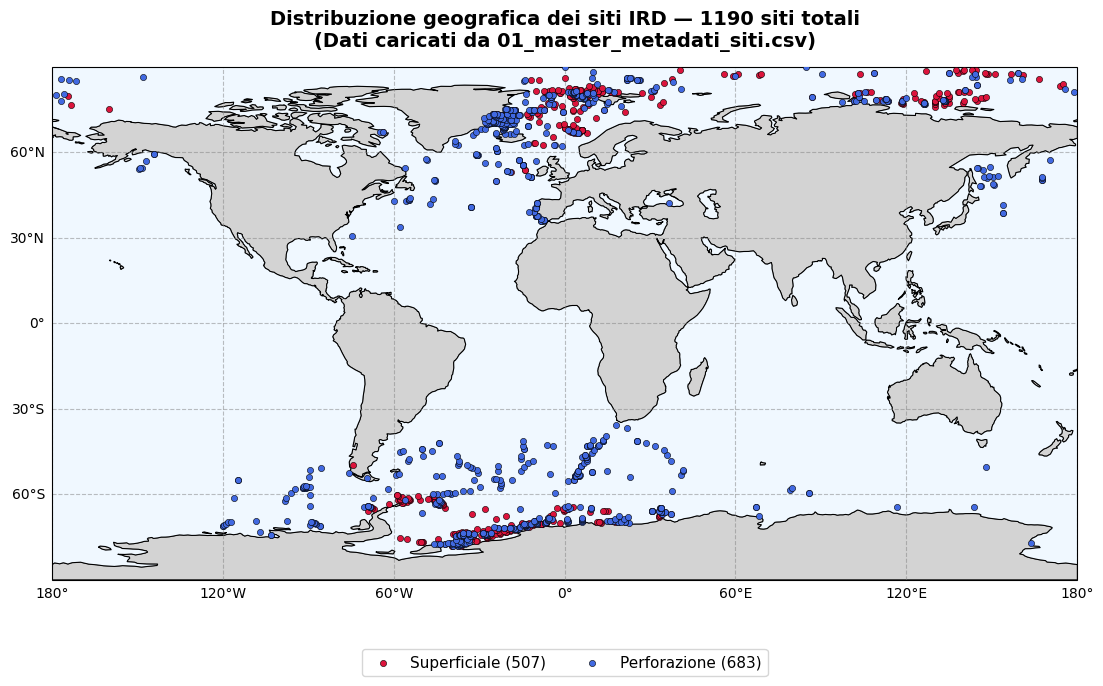

Master CSV: 1190 siti | Superficiali: 507 | Perforazioni: 683


In [70]:
df_master_ver = pd.read_csv(os.path.join(cartella_output, '01_master_metadati_siti.csv'))

fig = plt.figure(figsize=(14, 7))
ax = plt.axes(projection=crs.PlateCarree())
ax.set_global()
ax.add_feature(cfeature.LAND,      facecolor='lightgray', edgecolor='black', linewidth=0.5)
ax.add_feature(cfeature.OCEAN,     facecolor='aliceblue')
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5, color='gray')
gl.top_labels = False; gl.right_labels = False

for tipo, col in {'Superficiale': 'crimson', 'Perforazione': 'royalblue'}.items():
    sub = df_master_ver[df_master_ver['Tipo_Sito'] == tipo]
    ax.scatter(sub['Longitudine'], sub['Latitudine'],
               transform=crs.PlateCarree(), color=col,
               label=f"{tipo} ({len(sub)})",
               edgecolors='black', s=20, linewidths=0.4, zorder=5)

ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=11)
ax.set_title(
    f"Distribuzione geografica dei siti IRD — {len(df_master_ver)} siti totali\n"
    "(Dati caricati da 01_master_metadati_siti.csv)",
    fontsize=14, fontweight='bold', pad=15
)
plt.tight_layout()
plt.show()
print(f"Master CSV: {len(df_master_ver)} siti | "
      f"Superficiali: {(df_master_ver['Tipo_Sito']=='Superficiale').sum()} | "
      f"Perforazioni: {(df_master_ver['Tipo_Sito']=='Perforazione').sum()}")

## 2. Riproduzione grafiche dai file esportati

Caricamento file

In [71]:
percorso_verifica = os.path.join(cartella_output, '02_misure_superficiali_totale.csv')
df_verifica_mappa = pd.read_csv(percorso_verifica)

Riproduzione plot per verifica

In [1]:
fig = plt.figure(figsize=(12, 7))
ax = plt.axes(projection=crs.PlateCarree())
ax.set_global()

ax.add_feature(cfeature.LAND, facecolor='lightgray', edgecolor='black', linewidth=0.5)
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)

gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5, color='gray')
gl.top_labels = False; gl.right_labels = False

ax.set_title(
    "Misure superficiali — Indice IRD Armonizzato\n"
    "(Dati caricati da 02_misure_superficiali_totale.csv)",
    fontsize=14, fontweight='bold', pad=15)

val_max = df_verifica_mappa['Valore_Armonizzato'].max()

#scatter = ax.scatter(df_verifica_mappa['Longitudine'], df_verifica_mappa['Latitudine'],
#                     transform=crs.PlateCarree(),
#                     c=df_verifica_mappa['Valore_Armonizzato'], cmap='plasma',
#                     norm=mcolors.SymLogNorm(linthresh=0.1, vmin=0, vmax=val_max),
#                     s=40, edgecolors='black', linewidths=0.5, zorder=5)

import matplotlib.colors as colors

scatter = ax.scatter(df_verifica_mappa['Longitudine'], df_verifica_mappa['Latitudine'],
                     transform=crs.PlateCarree(),
                     c='white', 
                     s=20, edgecolors='black', linewidths=0.5, zorder=5)

scatter = ax.scatter(df_verifica_mappa['Longitudine'], df_verifica_mappa['Latitudine'],
                     transform=crs.PlateCarree(),
                     c=df_verifica_mappa['Valore_Armonizzato'], cmap='cool',
                     norm=colors.LogNorm(vmin=min(i for i in df_mappa2['IRD_Superficie'] if i > 0), vmax=df_mappa2['IRD_Superficie'].max()),
                     s=20, edgecolors='black', linewidths=0.5, zorder=5)

tck = [0, 0.1, 0.5, 1, 2, 5, 10]
cbar = plt.colorbar(scatter, orientation='horizontal', pad=0.1, aspect=40, ax=ax, ticks=tck)
cbar.ax.set_xticklabels([str(t) for t in tck])
cbar.set_label('Indice IRD Armonizzato (Scala Logaritmica)', fontsize=12)

plt.show()

NameError: name 'plt' is not defined

## 3. Riproduzione Serie Temporale/Profondità

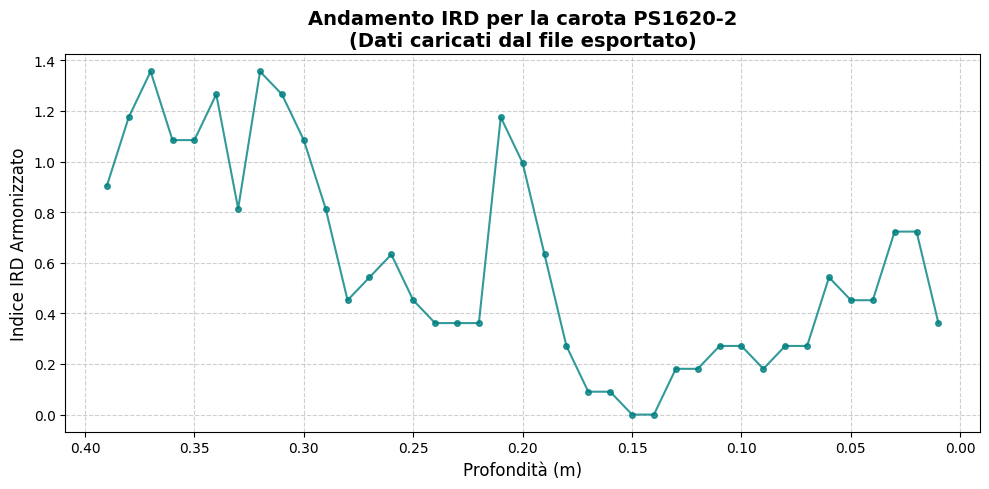

In [73]:
# Lista di tutti i CSV delle carote
file_carote = [f for f in os.listdir(cartella_carote) if f.endswith('.csv')]

if file_carote:
    # Primo file della lista
    file_scelto = file_carote[0]
    percorso_file = os.path.join(cartella_carote, file_scelto)

    df_carota_verifica = pd.read_csv(percorso_file)
    nome_sito_verifica = file_scelto.replace('.csv', '')

    plt.figure(figsize=(10, 5))

    # Controllo: se ci sono dati di Età, altrimenti usa la Profondità
    if df_carota_verifica['Eta_ka_BP'].notna().any():
        x_col = 'Eta_ka_BP'
        x_label = 'Età (ka BP)'
        df_plot = df_carota_verifica.dropna(subset=['Eta_ka_BP']).sort_values('Eta_ka_BP')
    else:
        x_col = 'Profondita_m'
        x_label = 'Profondità (m)'
        df_plot = df_carota_verifica.dropna(subset=['Profondita_m']).sort_values('Profondita_m')

    # Linea dell'IRD
    plt.plot(df_plot[x_col], df_plot['Valore_Armonizzato'], marker='o', linestyle='-', color='teal', markersize=4, alpha=0.8)

    plt.gca().invert_xaxis()

    plt.title(f"Andamento IRD per la carota {nome_sito_verifica}\n(Dati caricati dal file esportato)", fontsize=14, fontweight='bold')
    plt.xlabel(x_label, fontsize=12)
    plt.ylabel('Indice IRD Armonizzato', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()